In [11]:
import json
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

"""
TASK - 1
"""

#docs fetched, mock external API
def fetch_data():
    with open("docs.json","r",encoding="utf-8") as f:
        data=json.load(f)
    return data

data=fetch_data()
db=sqlite3.connect("1_neogrid.db")
crs=db.cursor()


#Create DB and store data in them
crs.execute(
    """
    CREATE TABLE IF NOT EXISTS documents (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        title TEXT NOT NULL,
        author TEXT NOT NULL,
        publication_year INTEGER
    )
    """
)

for d in data["books"]:
    crs.execute(
        """
        INSERT INTO documents (title,author,publication_year)
        VALUES(?,?,?)
        """,(
            d["title"],
            d["author"],
            d["publication_year"]
        )
    )

db.commit()


#Retrieve and display stored data
crs.execute(
    """
    SELECT * FROM documents
    """
)
disp=crs.fetchall()
for d in disp:
    print(d)
    print("\n")
    
crs.close()
db.close()

(1, 'Neuromancer', 'William Gibson', 1984)


(2, 'Snow Crash', 'Neal Stephenson', 1992)


(3, 'Do Androids Dream of Electric Sheep?', 'Philip K. Dick', 1968)


(4, 'Altered Carbon', 'Richard K. Morgan', 2002)


(5, 'Cyberpunk', 'William Gibson', 1988)


(6, 'Hardwired', 'Walter Jon Williams', 1986)


(7, 'The Windup Girl', 'Paolo Bacigalupi', 2009)


(8, 'Trouble and Her Friends', 'Melissa Scott', 1994)




82.91666666666667


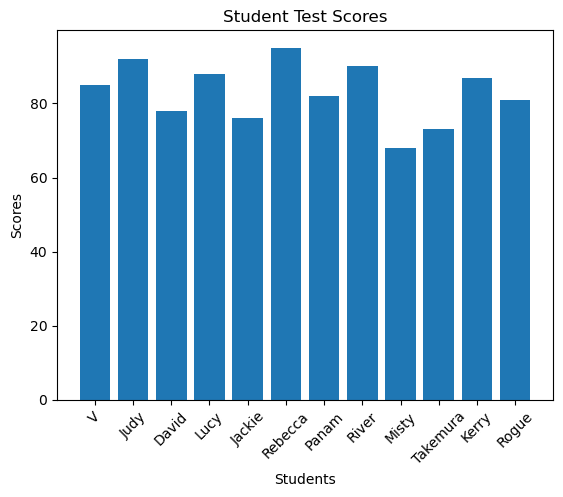

In [12]:
"""
TASK - 2
"""

def fetch_data():
    with open("docs.json","r",encoding="utf-8") as f:
        data=json.load(f)
    return data

data=fetch_data()

sum,avg=0,0
for s in data["scores"]:
    sum+=s["score"]
    avg+=1
    
print(sum/avg)

stud=[]
score=[]
for s in data["scores"]:
    stud.append(s["student"])
    score.append(s["score"])

plt.bar(stud,score)
plt.xlabel("Students")
plt.ylabel("Scores")
plt.title("Student Test Scores")
plt.xticks(rotation=45)

plt.show()


In [13]:
"""
TASK - 3
"""

df=pd.read_csv("neongrid.csv")

db=sqlite3.connect("3_neogrid.db")
crs=db.cursor()


crs.execute(
    """
    CREATE TABLE IF NOT EXISTS documents(
        employee_id STRING PRIMARY KEY,
        name TEXT NOT NULL,
        department TEXT NOT NULL,
        role TEXT NOT NULL,
        clearance_level INTEGER
    )
    """
)

for row in df.itertuples(index=False):
    crs.execute(
        """
        INSERT INTO documents (employee_id,name,department,role,clearance_level)
        VALUES (?,?,?,?,?)
        """,(
            row.employee_id,
            row.name,
            row.department,
            row.role,
            row.clearance_level
    )
    )
    
db.commit()

crs.execute(
    """
    SELECT * FROM documents
    """
)
disp=crs.fetchall()
for d in disp:
    print(d)
    print("\n")

('NC001', 'Hanako Arasaka', 'Identity', 'Migration Lead', 5)


('NC002', 'Takemura Goro', 'Payments', 'Integration Engineer', 4)


('NC003', 'Judy Alvarez', 'Analytics', 'Data Engineer', 3)


('NC004', 'Alt Cunningham', 'Analytics', 'System Architect', 5)


('NC005', 'Anders Hellman', 'Compliance', 'Compliance Officer', 4)


('NC006', 'David Martinez', 'Infrastructure', 'Deployment Engineer', 3)


('NC007', 'Lucy Kushinada', 'Security', 'Security Analyst', 5)


('NC008', 'Rogue Amendiares', 'Operations', 'Project Manager', 5)


('NC009', 'Rebecca', 'Infrastructure', 'Test Engineer', 2)


('NC010', 'Jackie Welles', 'Payments', 'API Developer', 3)


('NC011', 'Songbird', 'Security', 'Network Specialist', 5)


('NC012', 'V', 'Operations', 'System Tester', 4)


('NC013', 'Panam Palmer', 'Infrastructure', 'Field Engineer', 3)


('NC014', 'Kerry Eurodyne', 'Analytics', 'Data Analyst', 2)


('NC015', 'River Ward', 'Security', 'Incident Investigator', 4)




4 & 5 are in the report, provided in the assesment.